## Exercícios de Python e SQLite

* Nome: Letícia Souza Almeida
* Matéria: LABD
* Professor: Rafael Orsi 
* Data: 21/09/26


### <font color ="lightgreen">Importando Bibliotecas </font>

In [1]:
import requests
from bs4 import BeautifulSoup
import sqlite3
import pandas as pd

### <font color ="lightgreen">Parte 1: Configuração do Banco de Dados </font>

#### Criando o Banco de Dados

In [2]:
conn = sqlite3.connect('empresa.db')
cursor = conn.cursor()
print("Conexão com o banco de dados estabelecida.")

Conexão com o banco de dados estabelecida.


#### Criando Tabela e Verificação

Crie uma tabela chamada funcionários com as seguintes colunas:

* id(INTEGER,
* chave primária, incremento automático)
* nome(TEXTO, não nulo)
* cargo(TEXTO, não nulo)
* salario(REAL)
* data_contratacao(TEXT, não nulo)

In [3]:
# Criando a tabela no banco de dados
cursor.execute('''
    CREATE TABLE IF NOT EXISTS funcionarios (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        nome TEXT NOT NULL,
        cargo TEXT NOT NULL,
        salario REAL NOT NULL,
        data_contratacao TEXT NOT NULL
    );
''')

In [4]:
# Verificando a estrutura da tabela funcionarios
estrutura = cursor.execute("PRAGMA table_info(funcionarios);").fetchall()

for coluna in estrutura:
    print(coluna)

(0, 'id', 'INTEGER', 0, None, 1)
(1, 'nome', 'TEXT', 1, None, 0)
(2, 'cargo', 'TEXT', 1, None, 0)
(3, 'salario', 'REAL', 1, None, 0)
(4, 'data_contratacao', 'TEXT', 1, None, 0)


### <font color ="lightgreen">Parte 2: Manipulação de Dados (DML)</font>

#### Inserindo Dados 

In [5]:
cursor.execute(''' 
    INSERT INTO funcionarios (nome, cargo, salario, data_contratacao) 
    VALUES 
        ('João Silva', 'Analista de Sistemas', 5000.00, '2022-01-15'),
        ('Maria Oliveira', 'Gerente de Projetos', 7500.00, '2021-03-10'),
        ('Carlos Souza', 'Desenvolvedor Front-end', 4500.00, '2023-06-01'),
        ('Ana Costa', 'Designer UX/UI', 4800.00, '2022-11-20'),
        ('Pedro Lima', 'Engenheiro de Dados', 7000.00, '2021-08-05');
''')

print("Dados inseridos com sucesso!")

Dados inseridos com sucesso!


#### Consultando os Dados 

In [6]:
for row in cursor.execute("SELECT * FROM funcionarios"):
    print(row)

(1, 'João Silva', 'Analista de Sistemas', 5000.0, '2022-01-15')
(2, 'Maria Oliveira', 'Gerente de Projetos', 7500.0, '2021-03-10')
(3, 'Carlos Souza', 'Desenvolvedor Front-end', 4500.0, '2023-06-01')
(4, 'Ana Costa', 'Designer UX/UI', 4800.0, '2022-11-20')
(5, 'Pedro Lima', 'Engenheiro de Dados', 7000.0, '2021-08-05')


#### Filtros com WHERE 

* Selecione apenas os funcionários com salário superior a R$ 5.000.
* Selecione os funcionários que trabalham como 'Gerente'.

In [7]:
print("Funcionários com salário superior a 5000:\n")
for row in cursor.execute("SELECT * FROM funcionarios WHERE salario > 5000"):
    print(row)

Funcionários com salário superior a 5000:

(2, 'Maria Oliveira', 'Gerente de Projetos', 7500.0, '2021-03-10')
(5, 'Pedro Lima', 'Engenheiro de Dados', 7000.0, '2021-08-05')


In [8]:
print("Funcionários que trabalham como Gerente:\n")
# LIKE faz com que pesquise tudo o que tenha gerente, não preciando ser exatamente o texto
for row in cursor.execute("SELECT * FROM funcionarios WHERE cargo LIKE '%Gerente%'"):
    print(row)

Funcionários que trabalham como Gerente:

(2, 'Maria Oliveira', 'Gerente de Projetos', 7500.0, '2021-03-10')


#### Atualização de Dados 

Aumentando o salário da Ana Costa em 10%

In [26]:
# 1.1 -> representa o aumento de 10% no salário atual
cursor.execute("UPDATE funcionarios SET salario= (salario * 1.1) WHERE nome= 'Ana Costa';")
conn.commit() # Precisa salvar as alterações 
print("Valor do salário da Ana Costa atualizado")

Valor do salário da Ana Costa atualizado


#### Exclusão de Dados 

In [10]:
cursor.execute("DELETE FROM funcionarios WHERE nome='Carlos Souza';")
conn.commit()
print("Registro removido")

Registro removido


#### Contando o número de funcionários 

In [11]:
cursor.execute("SELECT COUNT(*) FROM funcionarios;")
cursor.fetchone()

(4,)

### <font color ="lightgreen">Parte 3: Agregação e Ordenação</font>

#### Funções de agregação ( SUM, AVG, MAX, MIN):

In [12]:
max_salario= cursor.execute("SELECT MAX(salario) FROM funcionarios;").fetchone()

min_salario= cursor.execute("SELECT MIN(salario) FROM funcionarios;").fetchone()

soma_salarios= cursor.execute("SELECT SUM(salario) FROM funcionarios;").fetchone()

media_salarios= cursor.execute("SELECT ROUND(AVG(salario),2) FROM funcionarios;").fetchone()

print("Funções de agregação:\n")
print(f"Salário máximo: {max_salario}")
print(f"Salário mínimo: {min_salario}")
print(f"Soma dos salários: {soma_salarios}")
print(f"Média dos salários: {media_salarios}")

Funções de agregação:

Salário máximo: (7500.0,)
Salário mínimo: (5000.0,)
Soma dos salários: (24780.0,)
Média dos salários: (6195.0,)


#### Agrupamento de dados ( GROUP BY):

* Calcule um salário médio para cada cargo.
* Conte quantos funcionários existem em cada cargo.

In [13]:
# Criando novos funcionários para demonstrar a função GROUP BY
cursor.execute("INSERT INTO funcionarios (nome, cargo, salario, data_contratacao) VALUES ('Bruno Martins', 'Analista de Sistemas', 5200.00, '2024-02-12')"),
cursor.execute("INSERT INTO funcionarios (nome, cargo, salario, data_contratacao) VALUES ('Juliana Rocha', 'Gerente de Projetos', 8200.00, '2023-09-18')"),
cursor.execute("INSERT INTO funcionarios (nome, cargo, salario, data_contratacao) VALUES ('Rafael Mendes', 'Engenheiro de Dados', 6800.00, '2024-01-25')")

In [14]:
cursor.execute("SELECT cargo, ROUND(AVG(salario), 2) FROM funcionarios GROUP BY cargo;")
cursor.fetchall()

[('Analista de Sistemas', 5100.0),
 ('Designer UX/UI', 5280.0),
 ('Engenheiro de Dados', 6900.0),
 ('Gerente de Projetos', 7850.0)]

In [15]:
cursor.execute("SELECT cargo, COUNT(*) FROM funcionarios GROUP BY cargo;")
cursor.fetchall()

[('Analista de Sistemas', 2),
 ('Designer UX/UI', 1),
 ('Engenheiro de Dados', 2),
 ('Gerente de Projetos', 2)]

#### Ordenação (ORDER BY):

* Selecione todos os funcionários e ordens de maior para o menor salário.
* Selecione todos os funcionários e ordene-os por nome em ordem alfabética.

In [16]:
cursor.execute("SELECT RANK() OVER (ORDER BY salario DESC) AS rank, nome, salario FROM funcionarios;")
cursor.fetchall()

[(1, 'Juliana Rocha', 8200.0),
 (2, 'Maria Oliveira', 7500.0),
 (3, 'Pedro Lima', 7000.0),
 (4, 'Rafael Mendes', 6800.0),
 (5, 'Ana Costa', 5280.0),
 (6, 'Bruno Martins', 5200.0),
 (7, 'João Silva', 5000.0)]

In [17]:
cursor.execute("SELECT * FROM funcionarios ORDER BY funcionarios.nome ASC;")
cursor.fetchall()

[(4, 'Ana Costa', 'Designer UX/UI', 5280.0, '2022-11-20'),
 (6, 'Bruno Martins', 'Analista de Sistemas', 5200.0, '2024-02-12'),
 (1, 'João Silva', 'Analista de Sistemas', 5000.0, '2022-01-15'),
 (7, 'Juliana Rocha', 'Gerente de Projetos', 8200.0, '2023-09-18'),
 (2, 'Maria Oliveira', 'Gerente de Projetos', 7500.0, '2021-03-10'),
 (5, 'Pedro Lima', 'Engenheiro de Dados', 7000.0, '2021-08-05'),
 (8, 'Rafael Mendes', 'Engenheiro de Dados', 6800.0, '2024-01-25')]

### <font color ="lightgreen">Parte 4: Transações e RollBack</font>

#### Simulação de transação:

* Iniciar uma transação.
* Insira um novo funcionário na tabela.
* Simule um erro (por exemplo, dividindo por zero ou forçando um erro) para acionar o except.
* Utilize conn.rollback()para reverter a transação e garantir que o novo funcionário não seja salvo no banco de dados.

In [19]:
try:
    conn.execute("BEGIN;")
    cursor.execute("INSERT INTO funcionarios (nome, cargo, salario, data_contratacao) VALUES ('Victor Lapa', 'Analista', 5000.00, '2023-01-01')") # Novo registro
    raise Exception("Erro proposital para teste de rollback")  # Simula um erro
    conn.commit()   
except:
    conn.rollback()
    print("Transação revertida devido a erro.")

Transação revertida devido a erro.


#### Transação com COMMIT:

* Inicie uma nova transação.
* Insira um novo funcionário.
* Não force o erro e use conn.commit()para salvar a operação permanentemente.
* Verifique se o novo funcionário agora faz parte da tabela.

In [20]:
try:
    conn.execute("BEGIN;")
    cursor.execute("INSERT INTO funcionarios (nome, cargo, salario, data_contratacao) VALUES ('Victor Lapa', 'Analista', 5000.00, '2023-01-01')") # Novo registro
    conn.commit() 
except:
    conn.rollback()
    print("Transação revertida devido a erro.")

In [22]:
cursor.execute("SELECT * FROM funcionarios;")
cursor.fetchall()

[(1, 'João Silva', 'Analista de Sistemas', 5000.0, '2022-01-15'),
 (2, 'Maria Oliveira', 'Gerente de Projetos', 7500.0, '2021-03-10'),
 (4, 'Ana Costa', 'Designer UX/UI', 5280.0, '2022-11-20'),
 (5, 'Pedro Lima', 'Engenheiro de Dados', 7000.0, '2021-08-05'),
 (6, 'Victor Lapa', 'Analista', 5000.0, '2023-01-01')]

### <font color ="lightgreen">Parte 5: Joins e Múltiplas Tabelas</font>

#### Criação de uma segunda tabela:
Crie uma nova tabela chamada departamentos com as colunas:
* id(INTEGER, chave primária, incremento automático)
* nome_departamento(TEXTO, não nulo)
* localizacao(TEXTO)

In [23]:
cursor.execute('''
    CREATE TABLE IF NOT EXISTS departamentos (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        nome_departamento TEXT NOT NULL,
        localizacao TEXT  
    );
    ''')
print("Tabela criada com sucesso!")

Tabela criada com sucesso!


In [25]:
cursor.execute(''' 
    INSERT INTO departamentos (nome_departamento, localizacao) 
    VALUES 
        ("Desenvolvimento Software", "São Paulo"),
        ("Diretores", "Rio de Janeiro"),
        ("Dados", "Belo Horizonte");
''')

print("Dados inseridos com sucesso!")

Dados inseridos com sucesso!


##### Alterando Tabela e Atualizando Dados

In [29]:
cursor.execute("""
    ALTER TABLE funcionarios
    ADD COLUMN departamento_id INTEGER
    REFERENCES departamentos(id);
""")

conn.commit()
print("Coluna departamento_id adicionada com sucesso!")

Coluna departamento_id adicionada com sucesso!
Coluna departamento_id adicionada com sucesso!


In [30]:
# Relacionando os Funcionários ao seu departamento
cursor.execute("""
    UPDATE funcionarios
    SET departamento_id = (
        SELECT id
        FROM departamentos
        WHERE nome_departamento =
            CASE
                WHEN cargo LIKE '%Gerente%' THEN 'Diretores'
                WHEN cargo LIKE '%Dados%' THEN 'Dados'
                ELSE 'Desenvolvimento Software'
            END
    );
""")

conn.commit()
print("Funcionários associados aos departamentos com sucesso!")

Funcionários associados aos departamentos com sucesso!


In [32]:
cursor.execute("SELECT * FROM funcionarios;")
cursor.fetchall()

[(1, 'João Silva', 'Analista de Sistemas', 5000.0, '2022-01-15', 1),
 (2, 'Maria Oliveira', 'Gerente de Projetos', 7500.0, '2021-03-10', 2),
 (4, 'Ana Costa', 'Designer UX/UI', 5808.000000000001, '2022-11-20', 1),
 (5, 'Pedro Lima', 'Engenheiro de Dados', 7000.0, '2021-08-05', 3),
 (6, 'Victor Lapa', 'Analista', 5000.0, '2023-01-01', 1)]

#### Inner Join:

Crie uma consulta que combine as tabelas funcionarios e departamentos para exibir o nome de cada funcionário junto com o nome do seu departamento.

In [33]:
print("INNER JOIN entre Funcionários e Departamentos:")

cursor.execute('''
    SELECT f.nome, f.cargo, f.salario, d.nome_departamento
    FROM funcionarios f
    INNER JOIN departamentos d ON f.departamento_id = d.id;
''')

for row in cursor.fetchall():
    print(f"Nome: {row[0]}\nCargo: {row[1]}\nSalário: {row[2]}\nDepartamento: {row[3]}\n\n")

INNER JOIN entre Funcionários e Departamentos:
Nome: João Silva
Cargo: Analista de Sistemas
Salário: 5000.0
Departamento: Desenvolvimento Software


Nome: Maria Oliveira
Cargo: Gerente de Projetos
Salário: 7500.0
Departamento: Diretores


Nome: Ana Costa
Cargo: Designer UX/UI
Salário: 5808.000000000001
Departamento: Desenvolvimento Software


Nome: Pedro Lima
Cargo: Engenheiro de Dados
Salário: 7000.0
Departamento: Dados


Nome: Victor Lapa
Cargo: Analista
Salário: 5000.0
Departamento: Desenvolvimento Software




#### Left Join:

1. Crie uma nova tabela chamada projetos com as colunas id e nome_projeto.

2. Crie uma tabela de particular funcionarios_projetos com funcionario_id e projeto_id para representar a relação de N para N.

3. Use um LEFT JOIN para listar todos os funcionários e, se houver, o nome do projeto em que estão.

In [34]:
# Criando a tabela projetos
cursor.execute("""
    CREATE TABLE IF NOT EXISTS projetos (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        nome_projeto TEXT NOT NULL
    );
""")

conn.commit()
print("Tabela projetos criada com sucesso!")

Tabela projetos criada com sucesso!


In [35]:
# Inserindo valores na tabela projetos 
cursor.execute("""
    INSERT INTO projetos (nome_projeto)
    VALUES 
        ("Sistema de Vendas"),
        ("Aplicativo Mobile"),
        ("Plataforma de Dados"),
        ("Redesign do Site");
""")

conn.commit()
print("Projetos inseridos com sucesso!")

Projetos inseridos com sucesso!


In [37]:
# Verificando os projetos inseridos
cursor.execute("SELECT * FROM projetos;")
cursor.fetchall()

[(1, 'Sistema de Vendas'),
 (2, 'Aplicativo Mobile'),
 (3, 'Plataforma de Dados'),
 (4, 'Redesign do Site')]

In [38]:
# Criando a tabela associativa para a relação N:N
cursor.execute("""
    CREATE TABLE IF NOT EXISTS funcionarios_projetos (
        funcionario_id INTEGER NOT NULL,
        projeto_id INTEGER NOT NULL,
        PRIMARY KEY (funcionario_id, projeto_id),
        FOREIGN KEY (funcionario_id) REFERENCES funcionarios(id),
        FOREIGN KEY (projeto_id) REFERENCES projetos(id)
    );
""")

conn.commit()
print("Tabela funcionarios_projetos criada com sucesso!")

Tabela funcionarios_projetos criada com sucesso!


In [39]:
# Inserindo relações entre funcionários e projetos
cursor.execute("""
    INSERT INTO funcionarios_projetos (funcionario_id, projeto_id)
    VALUES
        (1, 1),
        (1, 2),
        (2, 3),
        (4, 4),
        (5, 3),
        (7, 1),
        (7, 2);
""")

conn.commit()
print("Relações entre funcionários e projetos inseridas com sucesso!")

Relações entre funcionários e projetos inseridas com sucesso!


In [49]:
# Left Join entre funcionários e projetos
print("LEFT JOIN entre Funcionários e Projetos:\n")

cursor.execute('''
    SELECT 
        f.nome,
        f.cargo,
        p.nome_projeto
    FROM funcionarios f
    LEFT JOIN funcionarios_projetos fp
        ON f.id = fp.funcionario_id
    LEFT JOIN projetos p
        ON fp.projeto_id = p.id;
''')

for row in cursor.fetchall():
    print(f"Nome: {row[0]:<40}")
    print(f"Cargo: {row[1]:<30}")
    print(f"Projeto: {row[2] or 'Sem projeto':<40}")
    print()   

LEFT JOIN entre Funcionários e Projetos:

Nome: João Silva                              
Cargo: Analista de Sistemas          
Projeto: Sistema de Vendas                       

Nome: João Silva                              
Cargo: Analista de Sistemas          
Projeto: Aplicativo Mobile                       

Nome: Maria Oliveira                          
Cargo: Gerente de Projetos           
Projeto: Plataforma de Dados                     

Nome: Ana Costa                               
Cargo: Designer UX/UI                
Projeto: Redesign do Site                        

Nome: Pedro Lima                              
Cargo: Engenheiro de Dados           
Projeto: Plataforma de Dados                     

Nome: Victor Lapa                             
Cargo: Analista                      
Projeto: Sem projeto                             



In [50]:
# Fechando a conexão 
conn.close()

### <font color ="lightgreen">Parte 6: DCL (Controle de Dados)</font>

No seu notebook, explique em markdown a diferença entre DDL, DML, DQL e DCL,
focando em para que o DCL seja usado.

* **DDL:** (Data Definition Language) Definir e alterar estrutura do banco de dados (Create, Alter, Drop, Truncade)
* **DML:** (Data Manipulation Language) São os comandos que interagem com os dados dentro das tabelas. (Insert, Update, Delete)
* **DQL:** (Data Query Languag) São os comandos de consulta. (Select)
* **DCL:** (Data Control Language) São os comandos para controlar a parte de segurança do banco de dados, permissões. (Grant, Revoke)
* **DTL:** (Data Transaction Language) São os comandos para controle de transação. (Begin, Commit, Rollback)

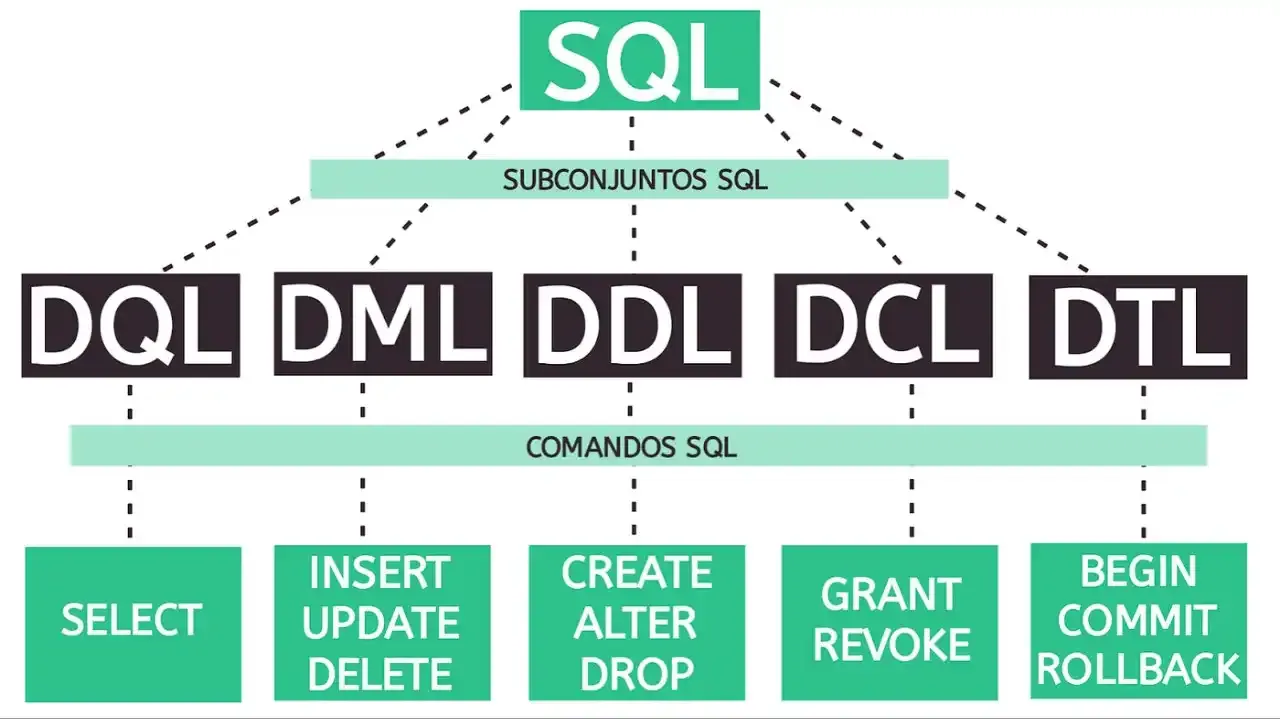